# LAB 07 — Transformer Architecture

Notebook này chạy toàn bộ phần code của LAB 07:

1. kiểm tra bài tính tay bằng NumPy (`transformer_block.py`, `positional_encoding.py`);
2. **Exp 1 + permutation**: positional encoding và "dog bites man" / "man bites dog";
3. dữ liệu IMDb (giống LAB 05), Transformer classifier tự ghép từ `TransformerBlock`;
4. **Exp 4**: LSTM vs Transformer (3 seed), thêm Transformer không PE và bản dùng `nn.TransformerEncoderLayer` để đối chiếu;
5. **Exp 2**: số head; **Exp 6**: mean vs CLS pooling; learning curves và confusion matrix;
6. **Exp 3**: attention của từng head; thứ tự từ trên model đã train;
7. **Exp 5**: sequence length; application; error analysis (attention so với occlusion).

In [1]:
import os, warnings
os.makedirs("images", exist_ok=True)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
warnings.filterwarnings("ignore")
import re, time, copy, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from scipy.stats import spearmanr
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import transformer_block as tb
import positional_encoding as pe_mod
from transformer_block import TransformerBlock, MultiHeadSelfAttention, count_params
from positional_encoding import positional_encoding, SinusoidalPE

QUICK = os.environ.get("LAB7_QUICK") == "1"          # chạy thử nhanh toàn bộ pipeline (không dùng cho kết quả)
try:
    display
except NameError:
    display = print
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 200)
SEED, SEEDS = 42, ([42] if QUICK else [42, 43, 44])
EPOCHS = 1 if QUICK else 6
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "", "| torch", torch.__version__)
results = []
def log(experiment, setting, metric, value):
    results.append({"experiment": experiment, "setting": setting, "metric": metric, "value": value})

Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU | torch 2.6.0+cu124


## 1. Kiểm tra bài tính tay (calculations.md)

Hai file `.py` có unit test riêng (`python transformer_block.py`, `python positional_encoding.py`). Ở đây chạy lại test và in đúng các số của bài tính tay.

In [2]:
tb.run_tests(); pe_mod.run_tests()
np.set_printoptions(precision=4, suppress=True)
B1 = tb.BAI1
r1 = tb.attention_head_np(B1["X"], B1["W_Q"], B1["W_K"], B1["W_V"])
print("\nBài 1 — một attention head (d_k = 2)")
for k in ("Q", "K", "V", "QK^T", "S", "A", "Z"):
    print(f"{k} =\n{r1[k]}")

# Bài 2: head 2 với W_Q = W_K = 0 → attention đều; concat rồi nhân W_O
W_V2 = np.array([[0, 1], [1, 0], [0, 0], [1, 1]], float)
r2 = tb.attention_head_np(B1["X"], np.zeros((4, 2)), np.zeros((4, 2)), W_V2)
concat = np.hstack([r1["Z"], r2["Z"]])
W_O = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [1, 0, 1, 0], [0, 1, 0, 1]], float)
print("\nBài 2 — head 2: V2 =\n", r2["V"], "\nA2 =\n", r2["A"], "\nZ2 =\n", r2["Z"])
print("Concat(head1, head2) ∈ R^{3×4} =\n", concat, "\nConcat · W_O =\n", concat @ W_O)

print("\nBài 3 — PE (d = 4, pos = 0, 1, 2):\n", positional_encoding(3, 4))
d_pe = positional_encoding(3, 4)
print("‖PE(0) − PE(1)‖ =", np.linalg.norm(d_pe[0] - d_pe[1]).round(4), "| ‖PE(1) − PE(2)‖ =", np.linalg.norm(d_pe[1] - d_pe[2]).round(4),
      "| ‖PE(0) − PE(2)‖ =", np.linalg.norm(d_pe[0] - d_pe[2]).round(4))

x = np.array([1., 2.]); W1, b1 = np.eye(2), np.array([0., -1.]); W2, b2 = np.array([[2., -1.], [1., 1.]]), np.array([0., 1.])
h = np.maximum(W1 @ x + b1, 0); yv = W2 @ h + b2
print("\nBài 4 — FFN: W1 x + b1 =", W1 @ x + b1, "→ h = ReLU =", h, "→ y = W2 h + b2 =", yv)
print("          (x = [1, 0]: W1 x + b1 =", W1 @ np.array([1., 0.]) + b1, "→ ReLU =", np.maximum(W1 @ np.array([1., 0.]) + b1, 0), ")")
v = np.array([2., 4., 6., 8.])
ln = (v - v.mean()) / np.sqrt(v.var() + 1e-5)
print("\nBài 5 — residual x + FFN(x) =", x + yv, "| LayerNorm([2, 4, 6, 8]) =", ln.round(4), "(mean", v.mean(), ", var", v.var(), ")")
ln_t = nn.LayerNorm(4, elementwise_affine=False)(torch.tensor(v, dtype=torch.float32)).numpy()
assert np.allclose(ln, ln_t, atol=1e-5)

print("\nBài 6 — shape trace (B = 8, T = 100, d_model = 128, n_heads = 4, d_ff = 256)")
tr = {}
blk = TransformerBlock(128, 4, 256).eval()
blk(torch.randn(8, 100, 128), trace=tr)
display(pd.DataFrame({"shape": {k: tuple(v) for k, v in tr.items()}}))
print("Tham số một block:", count_params(blk), "= MHA 4·(128² + 128) =", 4 * (128 * 128 + 128),
      "+ FFN", 128 * 256 + 256 + 256 * 128 + 128, "+ 2 LayerNorm", 4 * 128)
for heads in (1, 2, 4, 8):
    print(f"  n_heads = {heads}: d_k = {128 // heads}, Q/K/V {(8, heads, 100, 128 // heads)}, scores {(8, heads, 100, 100)}, "
          f"tham số MHA = {count_params(MultiHeadSelfAttention(128, heads))}")

transformer_block.py: 8 tests passed
positional_encoding.py: 5 tests passed

Bài 1 — một attention head (d_k = 2)
Q =
[[2. 0.]
 [0. 2.]
 [1. 1.]]
K =
[[2. 0.]
 [0. 1.]
 [1. 1.]]
V =
[[2. 1.]
 [0. 3.]
 [1. 1.]]
QK^T =
[[4. 0. 2.]
 [0. 2. 2.]
 [2. 1. 2.]]
S =
[[2.8284 0.     1.4142]
 [0.     1.4142 1.4142]
 [1.4142 0.7071 1.4142]]
A =
[[0.7679 0.0454 0.1867]
 [0.1084 0.4458 0.4458]
 [0.4011 0.1978 0.4011]]
Z =
[[1.7225 1.0908]
 [0.6626 1.8916]
 [1.2033 1.3956]]

Bài 2 — head 2: V2 =
 [[0. 1.]
 [2. 1.]
 [1. 1.]] 
A2 =
 [[0.3333 0.3333 0.3333]
 [0.3333 0.3333 0.3333]
 [0.3333 0.3333 0.3333]] 
Z2 =
 [[1. 1.]
 [1. 1.]
 [1. 1.]]
Concat(head1, head2) ∈ R^{3×4} =
 [[1.7225 1.0908 1.     1.    ]
 [0.6626 1.8916 1.     1.    ]
 [1.2033 1.3956 1.     1.    ]] 
Concat · W_O =
 [[2.7225 2.0908 1.     1.    ]
 [1.6626 2.8916 1.     1.    ]
 [2.2033 2.3956 1.     1.    ]]

Bài 3 — PE (d = 4, pos = 0, 1, 2):
 [[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02 

,shape
Q,"(8, 4, 100, 32)"
K,"(8, 4, 100, 32)"
V,"(8, 4, 100, 32)"
scores QKᵀ/√d_k,"(8, 4, 100, 100)"
attention A,"(8, 4, 100, 100)"
heads A·V,"(8, 4, 100, 32)"
concat,"(8, 100, 128)"
MHA output,"(8, 100, 128)"
FFN hidden (d_ff),"(8, 100, 256)"
FFN output,"(8, 100, 128)"


Tham số một block: 132480 = MHA 4·(128² + 128) = 66048 + FFN 65920 + 2 LayerNorm 512
  n_heads = 1: d_k = 128, Q/K/V (8, 1, 100, 128), scores (8, 1, 100, 100), tham số MHA = 66048
  n_heads = 2: d_k = 64, Q/K/V (8, 2, 100, 64), scores (8, 2, 100, 100), tham số MHA = 66048
  n_heads = 4: d_k = 32, Q/K/V (8, 4, 100, 32), scores (8, 4, 100, 100), tham số MHA = 66048
  n_heads = 8: d_k = 16, Q/K/V (8, 8, 100, 16), scores (8, 8, 100, 100), tham số MHA = 66048


## 2. Exp 1 — Positional encoding và permutation experiment

Một `TransformerBlock` khởi tạo ngẫu nhiên (d_model = 16, 2 head, d_ff = 32, không dropout, **chưa train**) và embedding ngẫu nhiên cho từng từ.
Câu đảo thứ tự dùng **cùng** embedding cho cùng một từ, nên khác biệt duy nhất giữa hai câu là thứ tự.
So sánh, với từng từ, representation của nó ở câu gốc và ở câu đảo; và vector câu (mean pooling).

In [3]:
set_seed()
D_TOY = 16
toy_block = TransformerBlock(D_TOY, 2, 32, dropout=0.0).eval()
toy_vocab = ["i", "love", "nlp", "dog", "bites", "man"]
toy_emb = {w: torch.randn(D_TOY) for w in toy_vocab}
toy_pe = torch.tensor(positional_encoding(8, D_TOY), dtype=torch.float32)

@torch.no_grad()
def toy_forward(words, use_pe):
    X = torch.stack([toy_emb[w] for w in words])
    if use_pe:
        X = X + toy_pe[: len(words)]
    Z, A = toy_block(X[None], return_attn=True)
    return Z[0], A[0]

perm_rows, perm_store = [], {}
for s1, s2 in [("i love nlp", "nlp love i"), ("dog bites man", "man bites dog")]:
    w1, w2 = s1.split(), s2.split()
    for use_pe in (False, True):
        Z1, A1 = toy_forward(w1, use_pe); Z2, A2 = toy_forward(w2, use_pe)
        perm_store[(s1, use_pe)] = (Z1, Z2, A1, A2)
        row = {"cặp câu": f"{s1} / {s2}", "positional info": "có PE" if use_pe else "không PE"}
        for w in w1:
            row[f"‖z({w}) S1 − z({w}) S2‖"] = float((Z1[w1.index(w)] - Z2[w2.index(w)]).norm())
        row["‖mean(Z S1) − mean(Z S2)‖"] = float((Z1.mean(0) - Z2.mean(0)).norm())
        row["‖Z S1 − Z S2‖ (so theo vị trí)"] = float((Z1 - Z2).norm())
        perm_rows.append(row)
        log("exp1 permutation (random block)", f"{s1} | {'PE' if use_pe else 'no PE'}", "mean-pooled diff", row["‖mean(Z S1) − mean(Z S2)‖"])
perm_df = pd.DataFrame(perm_rows)
for pair, g in perm_df.groupby("cặp câu", sort=False):
    display(g.dropna(axis=1).set_index("positional info").drop(columns="cặp câu").T.round(6))

Z1, Z2, A1, A2 = perm_store[("dog bites man", False)]
print("Không PE — attention head 1 của 'dog bites man' (hàng = query):\n", A1[0].numpy().round(3))
print("Không PE — attention head 1 của 'man bites dog':\n", A2[0].numpy().round(3))
print("→ hàng/cột chỉ bị hoán vị: A(S2) = P·A(S1)·Pᵀ:",
      torch.allclose(A2[0], A1[0][[2, 1, 0]][:, [2, 1, 0]], atol=1e-6))

positional info,không PE,có PE
‖z(i) S1 − z(i) S2‖,0.000000,1.208430
‖z(love) S1 − z(love) S2‖,0.000000,0.039837
‖z(nlp) S1 − z(nlp) S2‖,0.000001,1.383308
‖mean(Z S1) − mean(Z S2)‖,0.000000,0.089004
‖Z S1 − Z S2‖ (so theo vị trí),9.303660,7.947474


positional info,không PE,có PE
‖mean(Z S1) − mean(Z S2)‖,0.000000,0.278133
‖Z S1 − Z S2‖ (so theo vị trí),9.418031,9.135021
‖z(dog) S1 − z(dog) S2‖,0.000000,1.969327
‖z(bites) S1 − z(bites) S2‖,0.000000,0.225471
‖z(man) S1 − z(man) S2‖,0.000000,1.597338


Không PE — attention head 1 của 'dog bites man' (hàng = query):
 [[0.638 0.153 0.21 ]
 [0.125 0.419 0.456]
 [0.172 0.486 0.343]]
Không PE — attention head 1 của 'man bites dog':
 [[0.343 0.486 0.172]
 [0.456 0.419 0.125]
 [0.21  0.153 0.638]]
→ hàng/cột chỉ bị hoán vị: A(S2) = P·A(S1)·Pᵀ: True


**Hình `positional_encoding.png`:** (a) ma trận PE (50 vị trí × 128 chiều); (b) tích vô hướng PE(p)·PE(q): chỉ phụ thuộc |p − q|;
(c) khác biệt representation của từng từ giữa "dog bites man" và "man bites dog", không PE so với có PE.

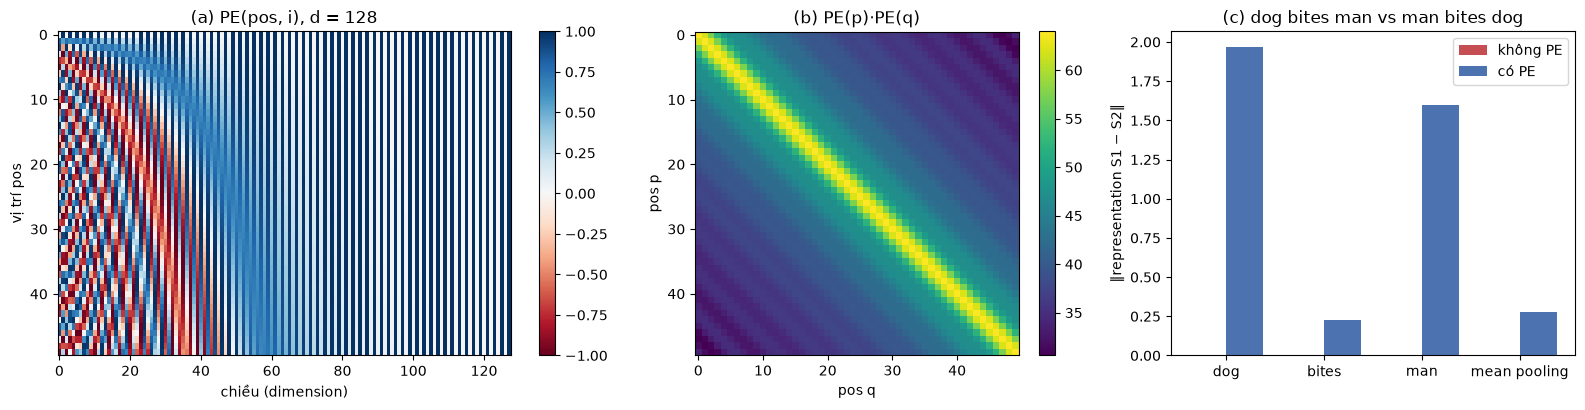

In [4]:
PE_BIG = positional_encoding(50, 128)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
im = ax[0].imshow(PE_BIG, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
ax[0].set_xlabel("chiều (dimension)"); ax[0].set_ylabel("vị trí pos"); ax[0].set_title("(a) PE(pos, i), d = 128"); plt.colorbar(im, ax=ax[0])
sim = PE_BIG @ PE_BIG.T
im = ax[1].imshow(sim, cmap="viridis"); ax[1].set_xlabel("pos q"); ax[1].set_ylabel("pos p"); ax[1].set_title("(b) PE(p)·PE(q)"); plt.colorbar(im, ax=ax[1])
dm = perm_df[perm_df["cặp câu"].str.startswith("dog")]
cols = [f"‖z({w}) S1 − z({w}) S2‖" for w in ("dog", "bites", "man")] + ["‖mean(Z S1) − mean(Z S2)‖"]
labels = ["dog", "bites", "man", "mean pooling"]
xx = np.arange(len(cols))
for k, (lbl, c) in enumerate((("không PE", "#c44e52"), ("có PE", "#4c72b0"))):
    vals = dm[dm["positional info"] == lbl][cols].values[0]
    ax[2].bar(xx + (k - 0.5) * 0.38, vals, width=0.38, color=c, label=lbl)
ax[2].set_xticks(xx, labels); ax[2].set_ylabel("‖representation S1 − S2‖")
ax[2].set_title("(c) dog bites man vs man bites dog"); ax[2].legend()
plt.tight_layout(); plt.savefig("images/positional_encoding.png", dpi=150); plt.show()

## 3. Dữ liệu IMDb (giống LAB 05 / LAB 06)

Train 19 923 / validation 4 981 (bỏ trùng lặp, chia stratified, seed 42) / test 25 000; vocabulary 25 000 từ phổ biến nhất của train.

In [5]:
ds = load_dataset("stanfordnlp/imdb")
train_raw, test_df = ds["train"].to_pandas(), ds["test"].to_pandas()
_BR, _NON, _SP = re.compile(r"<br\s*/?>", re.I), re.compile(r"[^a-z0-9'\s]"), re.compile(r"\s+")
def clean_text(t):
    return _SP.sub(" ", _NON.sub(" ", _BR.sub(" ", str(t).lower()))).strip()
def tokenize(t):
    return clean_text(t).split()
train_dedup = train_raw.drop_duplicates("text").reset_index(drop=True)
tr_df, va_df = train_test_split(train_dedup, test_size=0.2, stratify=train_dedup.label, random_state=SEED)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
if QUICK:
    tr_df, va_df, test_df = tr_df[:3000], va_df[:1000], test_df.sample(2000, random_state=SEED).reset_index(drop=True)
tok = {k: [tokenize(t) for t in d.text] for k, d in [("train", tr_df), ("val", va_df), ("test", test_df)]}
y = {"train": tr_df.label.values, "val": va_df.label.values, "test": test_df.label.values}
counts = Counter(w for t in tok["train"] for w in t)
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(25000)]
stoi = {w: i for i, w in enumerate(itos)}
PAD, UNK, MAX_LEN = 0, 1, 200
def encode(tokens, max_len=MAX_LEN):
    return ([stoi.get(w, UNK) for w in tokens] or [UNK])[:max_len]
def to_tensor(tok_lists, max_len=MAX_LEN):
    seqs = [encode(t, max_len) for t in tok_lists]
    X = np.zeros((len(seqs), max_len), dtype=np.int64)
    for i, s in enumerate(seqs):
        X[i, :len(s)] = s
    return torch.from_numpy(X), torch.tensor([len(s) for s in seqs])
_data_cache = {}
def get_data(max_len=MAX_LEN):
    if max_len not in _data_cache:
        _data_cache[max_len] = {k: to_tensor(tok[k], max_len) for k in ("train", "val", "test")}
    return _data_cache[max_len]
data = get_data()
test_len = np.array([len(t) for t in tok["test"]])
print(f"train {len(tr_df)} / validation {len(va_df)} / test {len(test_df)} | vocabulary {len(itos):,} | "
      f"độ dài test: trung vị {np.median(test_len):.0f}, trung bình {test_len.mean():.0f} token")

train 19923 / validation 4981 / test 25000 | vocabulary 25,002 | độ dài test: trung vị 172, trung bình 228 token


## 4. Model

**Transformer classifier** (Model B): Embedding (128) → + sinusoidal PE → `TransformerBlock` tự ghép (d_model 128, 4 head, d_ff 256, dropout 0.1) → pooling (mean trên token thật, hoặc [CLS]) → Dropout 0.3 → Linear.
**LSTM** (Model A): Embedding (128) → LSTM (hidden 128) → h<sub>T</sub> → Dropout 0.3 → Linear.
Hai model gần như cùng số tham số (≈ 3.33 triệu, phần lớn là embedding 25 002 × 128).

Chung cho mọi model: Adam lr 1e-3, batch 64, 6 epoch, clip gradient 1.0, chọn epoch có validation loss thấp nhất.

*Lưu ý kỹ thuật:* trên GPU của máy này, đôi khi (khoảng 1 lần / vài trăm bước) một forward pass cho ra NaN, và chạy lại **cùng** input, tham số, random state thì không còn NaN (đã kiểm tra 20 lần chạy lại).
Đây là lỗi tính toán không tất định của GPU, không phải của model, nhưng một bước NaN làm hỏng toàn bộ tham số qua Adam.
Vì vậy vòng train **bỏ qua bước có gradient không hữu hạn** (như `GradScaler` của AMP) và đếm số bước bị bỏ; khi dự đoán, batch nào ra NaN thì tính lại.
Tương tự, một lần chạy thử bị dừng vì `CUDNN_STATUS_INTERNAL_ERROR` (chạy lại thì không gặp), nên nếu gặp lỗi CUDA/cuDNN thì lần train đó được làm lại từ đầu với cùng seed (ghi vào `results.csv`).

In [6]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size=None, d_model=128, n_heads=4, d_ff=256, n_layers=1, pe="sin", pool="mean",
                 max_len=512, dropout=0.3, block_dropout=0.1, use_torch_layer=False):
        super().__init__()
        self.pool = pool
        self.emb = nn.Embedding(vocab_size or len(itos), d_model, padding_idx=PAD)
        self.pe = SinusoidalPE(d_model, max_len + 1) if pe == "sin" else None
        self.cls = nn.Parameter(torch.randn(d_model) * 0.02) if pool == "cls" else None
        if use_torch_layer:   # chỉ để đối chiếu: lớp có sẵn của PyTorch, cùng cấu hình (post-LN, ReLU)
            self.blocks = nn.ModuleList(nn.TransformerEncoderLayer(d_model, n_heads, d_ff, block_dropout, batch_first=True) for _ in range(n_layers))
        else:
            self.blocks = nn.ModuleList(TransformerBlock(d_model, n_heads, d_ff, block_dropout) for _ in range(n_layers))
        self.torch_layer = use_torch_layer
        self.drop, self.out = nn.Dropout(dropout), nn.Linear(d_model, 1)

    def forward(self, x, lengths=None, mask=None, return_attn=False):
        m = (x != PAD) if mask is None else mask              # True = token thật
        e = self.emb(x)
        if self.cls is not None:                              # [CLS] ở vị trí 0, các token dịch sang 1..T
            e = torch.cat([self.cls.expand(len(x), 1, -1), e], 1)
            m = torch.cat([torch.ones_like(m[:, :1]), m], 1)
        if self.pe is not None:
            e = self.pe(e)
        H, attns = e, []
        for blk in self.blocks:
            if self.torch_layer:
                H = blk(H, src_key_padding_mask=~m)
            else:
                H, A = blk(H, m, return_attn=True); attns.append(A)
        if self.pool == "cls":
            c = H[:, 0]
        else:
            mf = m.unsqueeze(-1).float(); c = (H * mf).sum(1) / mf.sum(1)
        logit = self.out(self.drop(c)).squeeze(-1)
        return (logit, attns[-1]) if return_attn else logit


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size=None, emb_dim=128, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size or len(itos), emb_dim, padding_idx=PAD)
        self.rnn = nn.LSTM(emb_dim, hidden, batch_first=True)
        self.drop, self.out = nn.Dropout(dropout), nn.Linear(hidden, 1)

    def forward(self, x, lengths, mask=None):
        packed = pack_padded_sequence(self.emb(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(packed)
        return self.out(self.drop(h[-1])).squeeze(-1)


def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}

def batches(X, lens, yv, bs, shuffle):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j].to(device), lens[j].to(device), (torch.as_tensor(yv[j.numpy()], dtype=torch.float32).to(device) if yv is not None else None)

@torch.no_grad()
def predict_logits(model, X, lens, bs=256):
    model.eval(); out = []
    for xb, lb, _ in batches(X, lens, None, bs, False):
        for _ in range(5):                                    # batch ra NaN (lỗi GPU) → tính lại
            o = model(xb, lb).float()
            if torch.isfinite(o).all():
                break
        out.append(o.cpu())
    return torch.cat(out)

store, curves, model_rows = {}, {}, []
def run(name, make_model, seed=SEED, max_len=MAX_LEN, keep=False, **kw):
    """Train + đánh giá. Lỗi CUDA/cuDNN chập chờn (không tái hiện khi chạy lại) → train lại từ đầu với cùng seed."""
    for attempt in range(3):
        try:
            return _run_once(name, make_model, seed, max_len, keep, **kw)
        except RuntimeError as e:
            if "CUDNN" not in str(e).upper() and "CUDA" not in str(e).upper():
                raise
            print(f"  [lỗi GPU: {str(e)[:60]}… → train lại {name}, seed {seed}]")
            log("GPU retries", f"{name} seed {seed} T={max_len}", "retry", attempt + 1)
            torch.cuda.empty_cache()
    raise RuntimeError("GPU lỗi 3 lần liên tiếp")

def _run_once(name, make_model, seed, max_len, keep, epochs=EPOCHS, bs=64, lr=1e-3):
    d = get_data(max_len)
    set_seed(seed)
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.BCEWithLogitsLoss()
    hist, best, best_state, skipped, train_time = [], (np.inf, 0), None, 0, 0.0
    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        for xb, lb, yb in batches(*d["train"], y["train"], bs, True):
            opt.zero_grad(); loss = lossf(model(xb, lb), yb); loss.backward()
            gn = nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            if not (torch.isfinite(loss) and torch.isfinite(gn)):
                skipped += 1; continue
            opt.step(); tot += loss.item() * len(yb); n += len(yb)
        if device.type == "cuda":
            torch.cuda.synchronize()
        train_time += time.time() - t0
        logits = predict_logits(model, *d["val"])
        vloss = float(nn.functional.binary_cross_entropy_with_logits(logits, torch.tensor(y["val"], dtype=torch.float32)))
        hist.append({"epoch": ep, "train loss": tot / n, "val loss": vloss, "val acc": accuracy_score(y["val"], logits.numpy() > 0)})
        if vloss < best[0]:
            best, best_state = (vloss, ep), copy.deepcopy(model.state_dict())
    mem = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else np.nan
    model.load_state_dict(best_state)
    prob = torch.sigmoid(predict_logits(model, *d["test"])).numpy()
    row = {"model": name, "seed": seed, "max_len": max_len, "params": count_params(model), "best epoch": best[1],
           "train time (s)": train_time, "s / epoch": train_time / epochs, "peak GPU mem (MB)": mem,
           "skipped steps": skipped, "best val loss": best[0], **metrics(y["test"], prob > 0.5)}
    model_rows.append(row)
    if seed == SEED:
        curves[(name, max_len)] = pd.DataFrame(hist)
        store[(name, max_len)] = {"prob": prob, **({"model": model} if keep else {})}
    print(f"{name:34s} seed {seed} T={max_len:3d} | acc {row['accuracy']:.4f} F1 {row['f1']:.4f} | best ep {best[1]} | "
          f"{train_time:5.1f}s | skipped {skipped}")
    return model

def summarize(names, max_len=MAX_LEN):
    df = pd.DataFrame(model_rows)
    df = df[df.model.isin(names) & (df.max_len == max_len)]
    agg = df.groupby("model", sort=False).agg(
        params=("params", "first"), runs=("seed", "count"), train_time=("train time (s)", "mean"), s_per_epoch=("s / epoch", "mean"),
        accuracy=("accuracy", "mean"), acc_std=("accuracy", "std"), precision=("precision", "mean"), recall=("recall", "mean"),
        f1=("f1", "mean"), f1_std=("f1", "std"), skipped=("skipped steps", "sum"))
    return agg.reindex(names)

## 5. Exp 4 — LSTM vs Transformer (3 seed)

Cùng dataset, split, vocabulary, embedding dimension (128), batch, optimizer, learning rate, số epoch. Mỗi model chạy 3 seed (42, 43, 44), báo cáo trung bình ± độ lệch chuẩn.
Thêm hai model để đối chiếu: Transformer **không** positional encoding (LO10) và Transformer dùng `nn.TransformerEncoderLayer` (cùng cấu hình, chỉ để kiểm tra block tự ghép).

In [7]:
MAIN = "Transformer (mean, PE)"
for s in SEEDS:
    run("LSTM", LSTMClassifier, seed=s, keep=(s == SEED))
    run(MAIN, lambda: TransformerClassifier(), seed=s, keep=(s == SEED))
    run("Transformer không PE", lambda: TransformerClassifier(pe="none"), seed=s, keep=(s == SEED))
run("Transformer (nn.TransformerEncoderLayer)", lambda: TransformerClassifier(use_torch_layer=True))
store_main = store[(MAIN, MAX_LEN)]["model"]
exp4 = summarize(["LSTM", MAIN, "Transformer không PE", "Transformer (nn.TransformerEncoderLayer)"])
display(exp4.round(4))
for name, r in exp4.iterrows():
    for k in ("params", "train_time", "accuracy", "acc_std", "precision", "recall", "f1", "f1_std", "skipped"):
        log("exp4 LSTM vs Transformer", name, k, r[k])
display(pd.DataFrame(model_rows)[["model", "seed", "accuracy", "f1", "best epoch", "train time (s)", "skipped steps"]].round(4))

LSTM                               seed 42 T=200 | acc 0.8344 F1 0.8339 | best ep 5 |  55.8s | skipped 0


Transformer (mean, PE)             seed 42 T=200 | acc 0.8338 F1 0.8357 | best ep 2 |  41.8s | skipped 1


Transformer không PE               seed 42 T=200 | acc 0.8400 F1 0.8445 | best ep 2 |  40.8s | skipped 0


LSTM                               seed 43 T=200 | acc 0.8249 F1 0.8187 | best ep 4 |  54.4s | skipped 0


Transformer (mean, PE)             seed 43 T=200 | acc 0.8398 F1 0.8402 | best ep 3 |  40.8s | skipped 1


Transformer không PE               seed 43 T=200 | acc 0.8306 F1 0.8214 | best ep 2 |  40.8s | skipped 0


... (2 outputs left out)

Transformer không PE               seed 44 T=200 | acc 0.8433 F1 0.8404 | best ep 3 |  42.6s | skipped 0


Transformer (nn.TransformerEncoderLayer) seed 42 T=200 | acc 0.8332 F1 0.8282 | best ep 2 |  46.6s | skipped 2


,params,runs,train_time,s_per_epoch,accuracy,acc_std,precision,recall,f1,f1_std,skipped
model,,,,,,,,,,,
LSTM,3332481,3,60.6803,10.1134,0.8253,0.0089,0.8446,0.7977,0.8202,0.0131,0
"Transformer (mean, PE)",3332865,3,41.8347,6.9725,0.8350,0.0043,0.8406,0.8275,0.8337,0.0077,2
Transformer không PE,3332865,3,41.4198,6.9033,0.8380,0.0066,0.8488,0.8243,0.8354,0.0123,0
Transformer (nn.TransformerEncoderLayer),3332865,1,46.5988,7.7665,0.8332,NaN,0.8539,0.8040,0.8282,NaN,2


,model,seed,accuracy,f1,best epoch,train time (s),skipped steps
0,LSTM,42,0.8344,0.8339,5,55.7816,0
1,"Transformer (mean, PE)",42,0.8338,0.8357,2,41.7968,1
2,Transformer không PE,42,0.8400,0.8445,2,40.7954,0
3,LSTM,43,0.8249,0.8187,4,54.4142,0
4,"Transformer (mean, PE)",43,0.8398,0.8402,3,40.8080,1
5,Transformer không PE,43,0.8306,0.8214,2,40.8232,0
6,LSTM,44,0.8166,0.8078,4,71.8451,0
7,"Transformer (mean, PE)",44,0.8315,0.8251,2,42.8994,0
8,Transformer không PE,44,0.8433,0.8404,3,42.6408,0
9,Transformer (nn.TransformerEncoderLayer),42,0.8332,0.8282,2,46.5988,2


## 6. Exp 2 — Số attention head (d_model = 128 cố định, 3 seed)

In [8]:
for hds in (1, 2, 8):
    for s in SEEDS:
        run(f"Transformer {hds} head", lambda: TransformerClassifier(n_heads=hds), seed=s, keep=(s == SEED and hds == 8))
head_names = {1: "Transformer 1 head", 2: "Transformer 2 head", 4: MAIN, 8: "Transformer 8 head"}
exp2 = summarize(list(head_names.values()))
exp2.insert(0, "heads", list(head_names)); exp2.insert(1, "d_k", [128 // h_ for h_ in head_names])
display(exp2[["heads", "d_k", "params", "train_time", "accuracy", "acc_std", "f1", "f1_std"]].round(4))
for name, r in exp2.iterrows():
    for k in ("d_k", "params", "train_time", "accuracy", "acc_std", "f1", "f1_std"):
        log("exp2 heads", f"{int(r.heads)} heads", k, r[k])

Transformer 1 head                 seed 42 T=200 | acc 0.8293 F1 0.8283 | best ep 2 |  28.2s | skipped 0


Transformer 1 head                 seed 43 T=200 | acc 0.8357 F1 0.8345 | best ep 3 |  26.8s | skipped 0


Transformer 1 head                 seed 44 T=200 | acc 0.8272 F1 0.8212 | best ep 2 |  27.0s | skipped 0


Transformer 2 head                 seed 42 T=200 | acc 0.8324 F1 0.8387 | best ep 2 |  35.2s | skipped 0


Transformer 2 head                 seed 43 T=200 | acc 0.8356 F1 0.8298 | best ep 3 |  33.6s | skipped 0


Transformer 2 head                 seed 44 T=200 | acc 0.8382 F1 0.8336 | best ep 3 |  33.5s | skipped 0


Transformer 8 head                 seed 42 T=200 | acc 0.8348 F1 0.8421 | best ep 2 |  60.7s | skipped 1


Transformer 8 head                 seed 43 T=200 | acc 0.8339 F1 0.8293 | best ep 3 |  59.7s | skipped 0


Transformer 8 head                 seed 44 T=200 | acc 0.8417 F1 0.8430 | best ep 3 |  59.6s | skipped 0


,heads,d_k,params,train_time,accuracy,acc_std,f1,f1_std
model,,,,,,,,
Transformer 1 head,1,128,3332865,27.3214,0.8308,0.0044,0.8280,0.0067
Transformer 2 head,2,64,3332865,34.0779,0.8354,0.0029,0.8340,0.0045
"Transformer (mean, PE)",4,32,3332865,41.8347,0.8350,0.0043,0.8337,0.0077
Transformer 8 head,8,16,3332865,59.9929,0.8368,0.0043,0.8381,0.0076


## 7. Exp 6 — Pooling: mean vs [CLS] (3 seed)

CLS-style: một vector [CLS] học được đặt ở vị trí 0 (nhận PE(0)), các token dịch sang vị trí 1..T; lấy output của [CLS] làm vector câu.

In [9]:
for s in SEEDS:
    run("Transformer (CLS, PE)", lambda: TransformerClassifier(pool="cls"), seed=s)
exp6 = summarize([MAIN, "Transformer (CLS, PE)"])
display(exp6[["accuracy", "acc_std", "f1", "f1_std", "train_time"]].round(4))
for name, r in exp6.iterrows():
    for k in ("accuracy", "acc_std", "f1", "f1_std", "train_time"):
        log("exp6 pooling", name, k, r[k])

Transformer (CLS, PE)              seed 42 T=200 | acc 0.8394 F1 0.8404 | best ep 4 |  43.3s | skipped 0


Transformer (CLS, PE)              seed 43 T=200 | acc 0.8382 F1 0.8361 | best ep 3 |  42.2s | skipped 0


Transformer (CLS, PE)              seed 44 T=200 | acc 0.8317 F1 0.8259 | best ep 2 |  42.1s | skipped 0


,accuracy,acc_std,f1,f1_std,train_time
model,,,,,
"Transformer (mean, PE)",0.8350,0.0043,0.8337,0.0077,41.8347
"Transformer (CLS, PE)",0.8365,0.0041,0.8341,0.0074,42.5629


## 8. Learning curves và confusion matrix (seed 42)

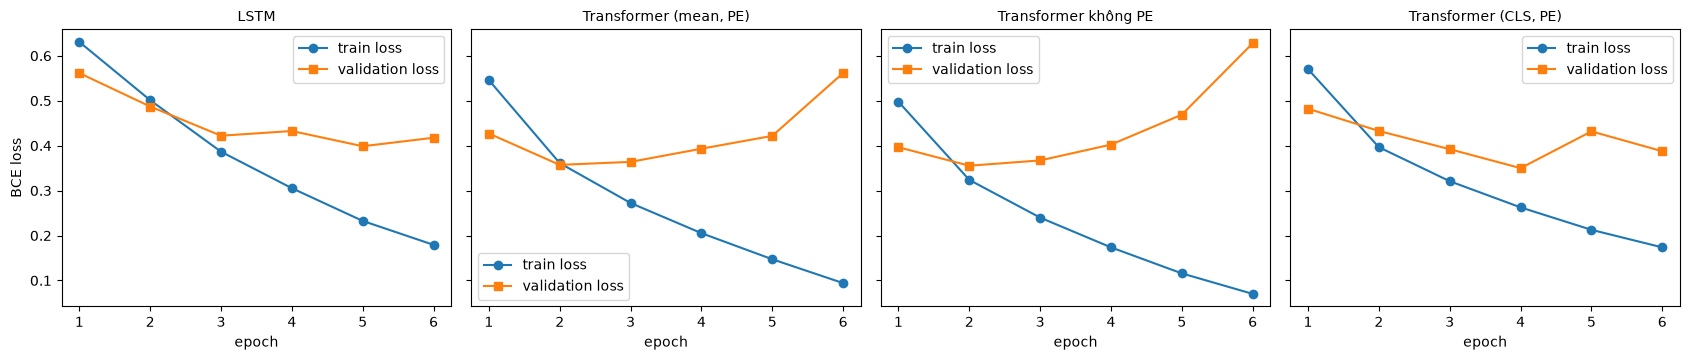

LSTM                  Transformer (mean, PE)                  Transformer không PE                  Transformer (CLS, PE)                 
      train loss val loss val acc             train loss val loss val acc           train loss val loss val acc            train loss val loss val acc
epoch                                                                                                                                                 
1         0.6307   0.5614  0.7193                 0.5457   0.4270  0.8004               0.4977   0.3964  0.8209                0.5702   0.4821  0.7677
2         0.5011   0.4870  0.7806                 0.3611   0.3571  0.8410               0.3237   0.3553  0.8462                0.3965   0.4326  0.7988
3         0.3865   0.4220  0.8165                 0.2723   0.3639  0.8444               0.2398   0.3671  0.8500                0.3208   0.3921  0.8229
4         0.3053   0.4325  0.8195                 0.2052   0.3932  0.8484               0.1736   0.4023  0.8472                0.2626   0.3499  0.8530
5         0.2325   0.3986  0.8480                 0.1471   0.4217  0.8498               0.1157   0.4689  0.8502                0.2127   0.4317  0.8490
6         0.1792   0.4175  0.8512                 0.0941   0.5617  0.8436               0.0701   0.6279  0.8436                0.1736   0.3875  0.8546

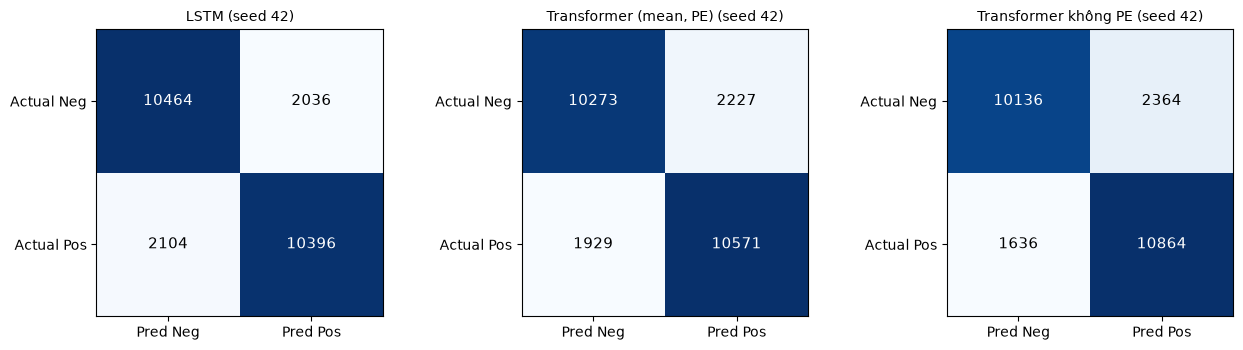

In [10]:
LC = ["LSTM", MAIN, "Transformer không PE", "Transformer (CLS, PE)"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.7), sharey=True)
for a_, name in zip(ax, LC):
    cv = curves[(name, MAX_LEN)]
    a_.plot(cv.epoch, cv["train loss"], marker="o", label="train loss"); a_.plot(cv.epoch, cv["val loss"], marker="s", label="validation loss")
    a_.set_title(name, fontsize=10); a_.set_xlabel("epoch"); a_.legend()
ax[0].set_ylabel("BCE loss"); plt.tight_layout(); plt.savefig("images/learning_curves.png", dpi=150); plt.show()
display(pd.concat({n: curves[(n, MAX_LEN)].set_index("epoch") for n in LC}, axis=1).round(4))
for n in LC:
    for _, r in curves[(n, MAX_LEN)].iterrows():
        log("learning curve", f"{n} | epoch {int(r.epoch)}", "train loss", r["train loss"]); log("learning curve", f"{n} | epoch {int(r.epoch)}", "val loss", r["val loss"])

CM = ["LSTM", MAIN, "Transformer không PE"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a_, name in zip(ax, CM):
    cm = confusion_matrix(y["test"], store[(name, MAX_LEN)]["prob"] > 0.5)
    a_.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a_.text(j, i, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
    a_.set_xticks([0, 1], ["Pred Neg", "Pred Pos"]); a_.set_yticks([0, 1], ["Actual Neg", "Actual Pos"]); a_.set_title(f"{name} (seed 42)", fontsize=10)
    log("confusion matrix", name, "TN FP FN TP", " ".join(map(str, cm.ravel())))
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=150); plt.show()

## 9. Exp 3 — Attention của từng head

Model 4 head (seed 42). Hình trên: attention matrix của 4 head cho một câu. Định lượng trên 500 review test (chỉ tính token thật):
max weight, entropy chuẩn hóa (1 = đều tuyệt đối), khối lượng attention vào chính nó, vào hai token kề bên (|i − j| = 1), khoảng cách trung bình |i − j|;
và **khoảng cách giữa các head**: total variation trung bình giữa hai hàng attention, TV = ½ Σ|a − b| (0 = giống hệt, 1 = không chồng lấn), so với cùng model lúc mới khởi tạo.

Model 4 head đã train:


,mean max weight,entropy / log L,self,kề bên |i−j|=1,mean |i−j|
head 1,0.1614,0.7875,0.0125,0.0144,55.0545
head 2,0.1750,0.7743,0.0076,0.0150,57.0125
head 3,0.2137,0.7347,0.0086,0.0144,54.9738
head 4,0.1318,0.8173,0.0099,0.0147,57.8217


Cùng model lúc khởi tạo (chưa train):


,mean max weight,entropy / log L,self,kề bên |i−j|=1,mean |i−j|
head 1,0.0219,0.9781,0.0076,0.0145,54.2502
head 2,0.0199,0.9820,0.0072,0.0151,54.2099
head 3,0.0210,0.9792,0.0073,0.0146,53.9932
head 4,0.0204,0.9805,0.0077,0.0145,53.3494


Model 8 head đã train:


,mean max weight,entropy / log L,self,kề bên |i−j|=1,mean |i−j|
head 1,0.1717,0.7700,0.0079,0.0135,55.5686
head 2,0.1564,0.8004,0.0086,0.0138,56.0515
head 3,0.2500,0.6920,0.0082,0.0150,55.0944
head 4,0.2245,0.7217,0.0078,0.0151,56.3737
head 5,0.1229,0.8224,0.0077,0.0148,55.2795
head 6,0.3110,0.6129,0.0090,0.0147,58.1129
head 7,0.2433,0.7006,0.0102,0.0144,55.3530
head 8,0.1422,0.8062,0.0071,0.0144,55.5688


,TV trung bình giữa các cặp head,TV nhỏ nhất (cặp giống nhau nhất),TV lớn nhất
"4 head, đã train",0.6341,0.6052,0.6601
"4 head, khởi tạo",0.2481,0.2378,0.2647
"8 head, đã train",0.6776,0.5893,0.7866


TV giữa từng cặp head (4 head, đã train):


,head 1,head 2,head 3,head 4
head 1,0.000,0.644,0.649,0.622
head 2,0.644,0.000,0.660,0.605
head 3,0.649,0.660,0.000,0.624
head 4,0.622,0.605,0.624,0.000


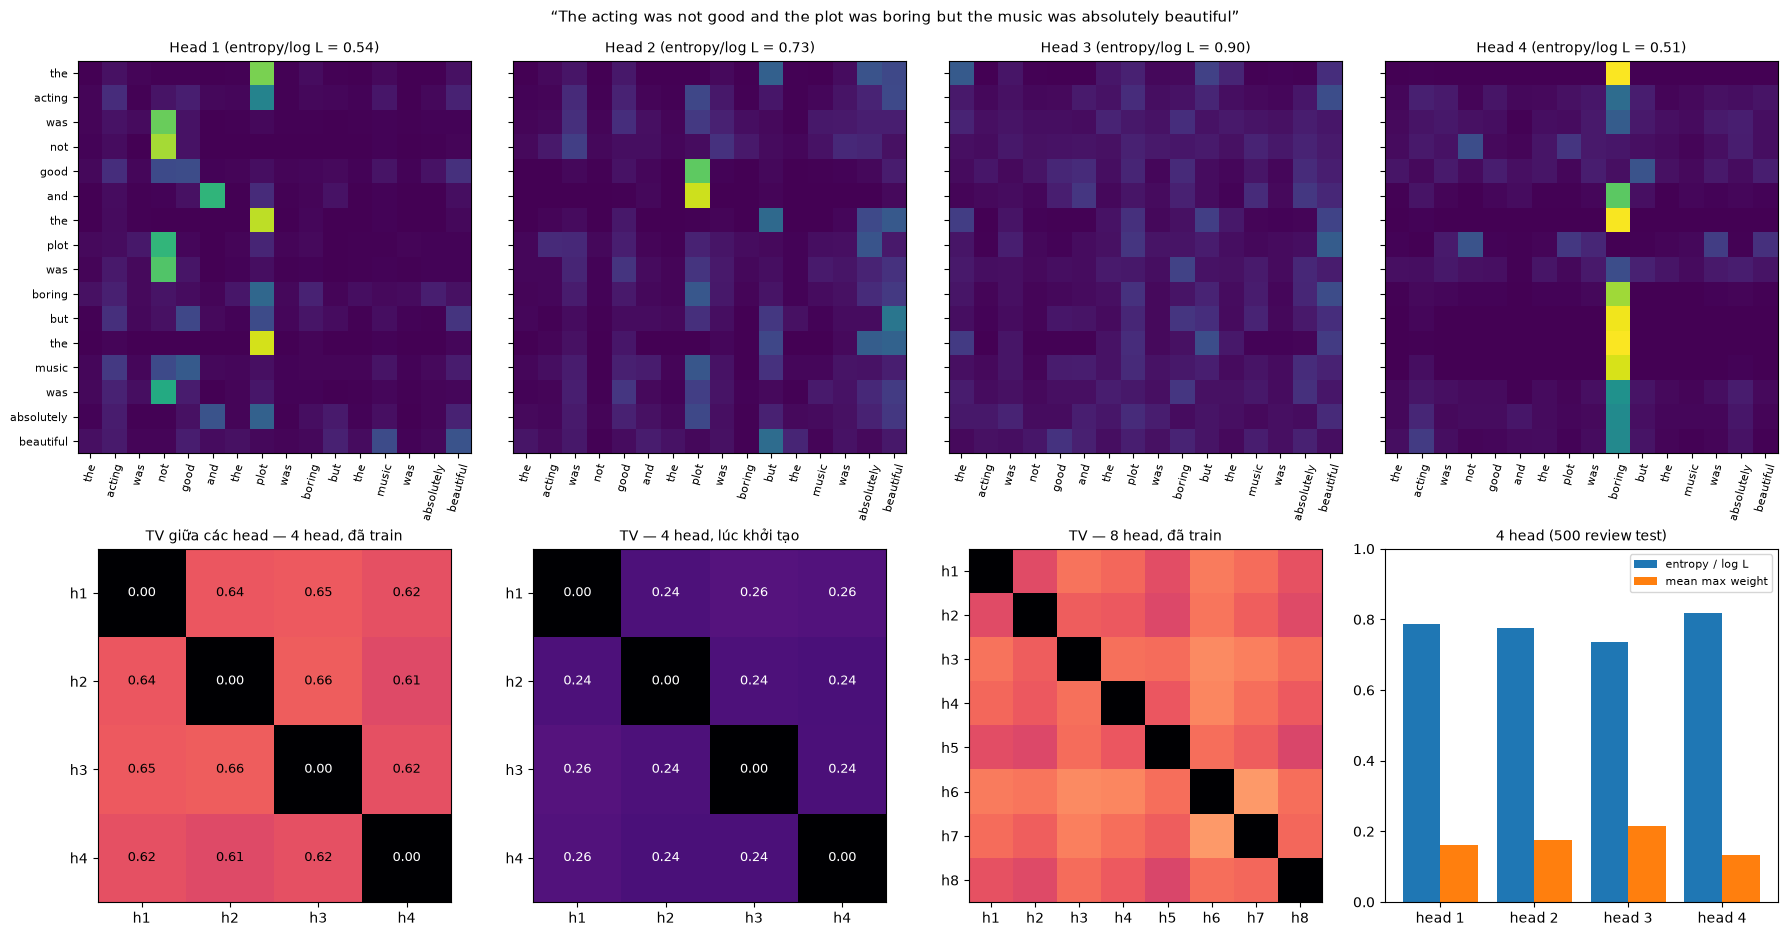

In [11]:
@torch.no_grad()
def get_attn(model, X):
    model.eval()
    _, A = model(X.to(device), return_attn=True)
    return A.cpu().numpy()                                   # (B, h, T, T)

def head_stats(model, n=500, bs=100):
    Xs, Ls = data["test"][0][:n], data["test"][1][:n].numpy()
    rows, tv_sum, cnt = None, None, 0
    for i in range(0, n, bs):
        A = get_attn(model, Xs[i:i + bs])
        H = A.shape[1]
        if rows is None:
            rows = {k: np.zeros(H) for k in ("max", "ent", "self", "adj", "dist")}; tv_sum = np.zeros((H, H))
        for b in range(len(A)):
            L = Ls[i + b]
            if L < 3:
                continue
            a = A[b, :, :L, :L]                              # (h, L, L)
            idx = np.arange(L); dist = np.abs(idx[:, None] - idx[None, :])
            rows["max"] += a.max(-1).mean(-1)
            rows["ent"] += (-(a * np.log(a + 1e-12)).sum(-1)).mean(-1) / np.log(L)
            rows["self"] += np.einsum("hii->h", a) / L
            rows["adj"] += (a * (dist == 1)).sum(-1).mean(-1)
            rows["dist"] += (a * dist).sum(-1).mean(-1)
            tv_sum += 0.5 * np.abs(a[:, None] - a[None, :]).sum(-1).mean(-1)
            cnt += 1
    stats = pd.DataFrame({"mean max weight": rows["max"], "entropy / log L": rows["ent"], "self": rows["self"],
                          "kề bên |i−j|=1": rows["adj"], "mean |i−j|": rows["dist"]}) / cnt
    stats.index = [f"head {k + 1}" for k in range(len(stats))]
    return stats, tv_sum / cnt

m4, m8 = store[(MAIN, MAX_LEN)]["model"], store[("Transformer 8 head", MAX_LEN)]["model"]
set_seed(SEED); m4_init = TransformerClassifier().to(device)
st4, tv4 = head_stats(m4); st4i, tv4i = head_stats(m4_init); st8, tv8 = head_stats(m8)
print("Model 4 head đã train:"); display(st4.round(4))
print("Cùng model lúc khởi tạo (chưa train):"); display(st4i.round(4))
print("Model 8 head đã train:"); display(st8.round(4))
offdiag = lambda m: m[~np.eye(len(m), dtype=bool)]
tv_tab = pd.DataFrame({"TV trung bình giữa các cặp head": [offdiag(tv4).mean(), offdiag(tv4i).mean(), offdiag(tv8).mean()],
                       "TV nhỏ nhất (cặp giống nhau nhất)": [offdiag(tv4).min(), offdiag(tv4i).min(), offdiag(tv8).min()],
                       "TV lớn nhất": [offdiag(tv4).max(), offdiag(tv4i).max(), offdiag(tv8).max()]},
                      index=["4 head, đã train", "4 head, khởi tạo", "8 head, đã train"])
display(tv_tab.round(4)); print("TV giữa từng cặp head (4 head, đã train):"); display(pd.DataFrame(tv4, index=st4.index, columns=st4.index).round(3))
for lbl, st in (("4 heads trained", st4), ("4 heads init", st4i), ("8 heads trained", st8)):
    for hname, r in st.iterrows():
        for k, v in r.items():
            log("exp3 head stats (500 test reviews)", f"{lbl} | {hname}", k, v)
for idx_, r in tv_tab.iterrows():
    for k, v in r.items():
        log("exp3 head distance (TV)", idx_, k, v)

SENT_H = "The acting was not good and the plot was boring but the music was absolutely beautiful"
toks_h = tokenize(SENT_H)
Xh, _ = to_tensor([toks_h])
Ah = get_attn(m4, Xh)[0][:, :len(toks_h), :len(toks_h)]
fig = plt.figure(figsize=(18, 9.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1.25, 1])
for k in range(4):
    a_ = fig.add_subplot(gs[0, k])
    a_.imshow(Ah[k], cmap="viridis", vmin=0, vmax=1)
    a_.set_xticks(range(len(toks_h)), toks_h, rotation=75, fontsize=8); a_.set_yticks(range(len(toks_h)), toks_h if k == 0 else [], fontsize=8)
    ent = (-(Ah[k] * np.log(Ah[k] + 1e-12)).sum(-1)).mean() / np.log(len(toks_h))
    a_.set_title(f"Head {k + 1} (entropy/log L = {ent:.2f})", fontsize=10)
for k, (mat, ttl) in enumerate(((tv4, "TV giữa các head — 4 head, đã train"), (tv4i, "TV — 4 head, lúc khởi tạo"), (tv8, "TV — 8 head, đã train"))):
    a_ = fig.add_subplot(gs[1, k])
    im = a_.imshow(mat, cmap="magma", vmin=0, vmax=1)
    if len(mat) <= 4:
        for (i, j), v in np.ndenumerate(mat):
            a_.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black", fontsize=9)
    a_.set_xticks(range(len(mat)), [f"h{i + 1}" for i in range(len(mat))]); a_.set_yticks(range(len(mat)), [f"h{i + 1}" for i in range(len(mat))])
    a_.set_title(ttl, fontsize=10)
a_ = fig.add_subplot(gs[1, 3])
xb_ = np.arange(4)
a_.bar(xb_ - 0.2, st4["entropy / log L"], 0.4, label="entropy / log L"); a_.bar(xb_ + 0.2, st4["mean max weight"], 0.4, label="mean max weight")
a_.set_xticks(xb_, st4.index); a_.set_ylim(0, 1); a_.legend(fontsize=8); a_.set_title("4 head (500 review test)", fontsize=10)
fig.suptitle(f"“{SENT_H}”", fontsize=11)
plt.tight_layout(); plt.savefig("images/attention_heads.png", dpi=150); plt.show()

### Thứ tự từ trên model đã train

Cùng tập từ, khác thứ tự. Model không PE phải cho cùng xác suất (khác biệt chỉ do sai số số học).

In [12]:
@torch.no_grad()
def prob_of(model, texts, max_len=MAX_LEN):
    X, l = to_tensor([tokenize(t) for t in texts], max_len)
    return torch.sigmoid(predict_logits(model, X, l)).numpy()

ORDER = [("dog bites man", "man bites dog"),
         ("I do not like this movie", "not I do like this movie"),
         ("the movie was not good it was bad", "the movie was bad it was not good"),
         ("I expected it to be bad but it was actually wonderful", "I expected it to be wonderful but it was actually bad")]
order_models = {"LSTM": store[("LSTM", MAX_LEN)]["model"], MAIN: store_main, "Transformer không PE": store[("Transformer không PE", MAX_LEN)]["model"]}
order_rows = []
for a_txt, b_txt in ORDER:
    for name, mdl in order_models.items():
        pa, pb = prob_of(mdl, [a_txt, b_txt])
        order_rows.append({"model": name, "câu gốc": a_txt, "câu đảo": b_txt, "P(pos) gốc": pa, "P(pos) đảo": pb, "|ΔP|": abs(pa - pb)})
order_df = pd.DataFrame(order_rows)
display(order_df.round(4))
for name, g in order_df.groupby("model", sort=False):
    print(f"{name:26s} max |ΔP| khi đảo thứ tự = {g['|ΔP|'].max():.2e}")
    log("order sensitivity (trained)", name, "max |ΔP| when reordering", g["|ΔP|"].max())

,model,câu gốc,câu đảo,P(pos) gốc,P(pos) đảo,|ΔP|
0,LSTM,dog bites man,man bites dog,0.6534,0.6218,0.0317
1,"Transformer (mean, PE)",dog bites man,man bites dog,0.9575,0.9511,0.0064
2,Transformer không PE,dog bites man,man bites dog,0.3169,0.3169,0.0000
3,LSTM,I do not like this movie,not I do like this movie,0.5464,0.5119,0.0345
4,"Transformer (mean, PE)",I do not like this movie,not I do like this movie,0.0033,0.0047,0.0014
5,Transformer không PE,I do not like this movie,not I do like this movie,0.0022,0.0022,0.0000
6,LSTM,the movie was not good it was bad,the movie was bad it was not good,0.0886,0.1922,0.1035
7,"Transformer (mean, PE)",the movie was not good it was bad,the movie was bad it was not good,0.0065,0.0051,0.0014
8,Transformer không PE,the movie was not good it was bad,the movie was bad it was not good,0.0028,0.0028,0.0000
9,LSTM,I expected it to be bad but it was actually wonderful,I expected it to be wonderful but it was actually bad,0.6577,0.2580,0.3996


LSTM                       max |ΔP| khi đảo thứ tự = 4.00e-01
Transformer (mean, PE)     max |ΔP| khi đảo thứ tự = 1.15e-01
Transformer không PE       max |ΔP| khi đảo thứ tự = 8.94e-08


## 10. Exp 5 — Sequence length

Train Transformer (4 head, seed 42) với max_length 32 / 64 / 128 / 256.
*Tokens retained*: tỉ lệ token của test còn lại sau khi cắt; *attention memory*: số phần tử của attention matrix trong một batch (64 × 4 head × T × T, float32) cho **một** lớp — chưa kể bản lưu lại cho backward.
Sau đó đo riêng chi phí một bước train (batch 64) của LSTM và Transformer với T tới 2 048.

Transformer (mean, PE)             seed 42 T= 32 | acc 0.6989 F1 0.7038 | best ep 2 |  14.9s | skipped 0


Transformer (mean, PE)             seed 42 T= 64 | acc 0.7528 F1 0.7764 | best ep 2 |  19.7s | skipped 0


Transformer (mean, PE)             seed 42 T=128 | acc 0.8050 F1 0.7962 | best ep 2 |  24.5s | skipped 4


Transformer (mean, PE)             seed 42 T=256 | acc 0.8456 F1 0.8466 | best ep 2 |  54.1s | skipped 0
(tham chiếu max_length 200, seed 42: accuracy 0.8338, F1 0.8357, 41.8s)


,Tokens retained,% review không bị cắt,T²,"Attention memory (MB, 64×4×T², 1 lớp)",Peak GPU mem train (MB),Training time (s),Accuracy,F1
Length,,,,,,,,
32,0.1400,0.0034,1024,1.0,280.0801,14.8577,0.6989,0.7038
64,0.2768,0.0548,4096,4.0,332.1548,19.7277,0.7528,0.7764
128,0.5207,0.2669,16384,16.0,484.3047,24.5218,0.8050,0.7962
256,0.7754,0.7208,65536,64.0,980.6045,54.0543,0.8456,0.8466


ms / bước train (B = 64)             peak GPU MB            
model                     LSTM Transformer        LSTM Transformer
T                                                                 
32                         9.5         8.2       242.8       244.3
64                        12.4         8.5       252.7       263.6
128                       17.7        11.2       278.8       326.2
256                       29.1        26.7       330.8       515.4
512                       56.4        79.8       402.9      1323.5
1024                      97.8      1122.9       579.1      4475.8
2048                     217.5         NaN       931.6         NaN

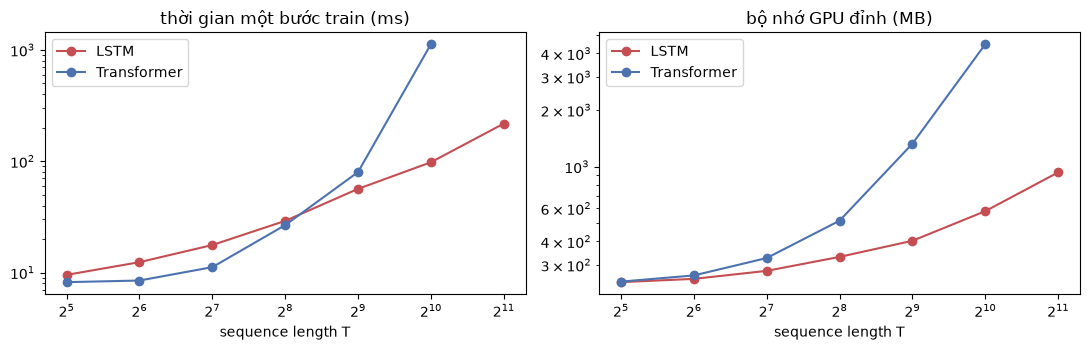

In [13]:
LENS = [32, 64, 128, 256]
for L in LENS:
    run(MAIN, lambda: TransformerClassifier(), max_len=L)
len_rows = []
for L in LENS:
    r = [m for m in model_rows if m["model"] == MAIN and m["max_len"] == L][-1]
    len_rows.append({"Length": L, "Tokens retained": np.minimum(test_len, L).sum() / test_len.sum(),
                     "% review không bị cắt": (test_len <= L).mean(), "T²": L * L,
                     "Attention memory (MB, 64×4×T², 1 lớp)": 64 * 4 * L * L * 4 / 2**20,
                     "Peak GPU mem train (MB)": r["peak GPU mem (MB)"], "Training time (s)": r["train time (s)"],
                     "Accuracy": r["accuracy"], "F1": r["f1"]})
exp5 = pd.DataFrame(len_rows).set_index("Length")
r200 = [m for m in model_rows if m["model"] == MAIN and m["max_len"] == MAX_LEN and m["seed"] == SEED][0]
print(f"(tham chiếu max_length 200, seed 42: accuracy {r200['accuracy']:.4f}, F1 {r200['f1']:.4f}, {r200['train time (s)']:.1f}s)")
display(exp5.round(4))
for L, r in exp5.iterrows():
    for k, v in r.items():
        log("exp5 sequence length (Transformer)", f"max_len={L}", k, v)

def bench(make_model, T, B=64, reps=5):
    set_seed(); model = make_model().to(device).train()
    opt = torch.optim.Adam(model.parameters()); lossf = nn.BCEWithLogitsLoss()
    x = torch.randint(2, len(itos), (B, T), device=device); l = torch.full((B,), T); yb = torch.randint(0, 2, (B,), device=device).float()
    try:
        for i in range(reps + 2):
            if i == 2:
                torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.perf_counter()
            opt.zero_grad(); lossf(model(x, l), yb).backward(); opt.step()
        torch.cuda.synchronize()
        return (time.perf_counter() - t0) / reps * 1000, torch.cuda.max_memory_allocated() / 2**20
    except torch.cuda.OutOfMemoryError:
        return np.nan, np.nan
    finally:
        del model, opt; torch.cuda.empty_cache()

bench_rows = []
if device.type == "cuda":
    for mk in (LSTMClassifier, TransformerClassifier):        # warm-up
        bench(mk, 64)
    for T in [32, 64, 128, 256, 512, 1024, 2048]:
        for name, mk in (("LSTM", LSTMClassifier), ("Transformer", lambda: TransformerClassifier(max_len=2048))):
            ms, mb = bench(mk, T)
            bench_rows.append({"T": T, "model": name, "ms / bước train (B = 64)": ms, "peak GPU MB": mb})
            log("cost vs T (1 train step, B=64)", f"{name} T={T}", "ms", ms); log("cost vs T (1 train step, B=64)", f"{name} T={T}", "peak MB", mb)
    bench_df = pd.DataFrame(bench_rows).pivot(index="T", columns="model")
    display(bench_df.round(1))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for name, c in (("LSTM", "#c44e52"), ("Transformer", "#4c72b0")):
        g = pd.DataFrame(bench_rows).query("model == @name")
        ax[0].plot(g["T"], g["ms / bước train (B = 64)"], marker="o", color=c, label=name)
        ax[1].plot(g["T"], g["peak GPU MB"], marker="o", color=c, label=name)
    for a_, t in ((ax[0], "thời gian một bước train (ms)"), (ax[1], "bộ nhớ GPU đỉnh (MB)")):
        a_.set_xscale("log", base=2); a_.set_yscale("log"); a_.set_xlabel("sequence length T"); a_.set_title(t); a_.legend()
    plt.tight_layout(); plt.savefig("images/cost.png", dpi=150); plt.show()

## 11. Application — Transformer text classification

Raw text → tokenizer → token IDs → embedding → PE → Transformer Encoder → mean pooling → Linear → P(positive). Model: Transformer 4 head, seed 42.
Thêm cột Transformer không PE và LSTM (seed 42) để so sánh.

In [14]:
lstm42 = store[("LSTM", MAX_LEN)]["model"]
APP = [("I really enjoyed this movie.", "câu ngắn", 1),
       ("Great film.", "câu ngắn", 1),
       ("I went in with low expectations because the trailer looked cheap, but the story kept surprising me, the two leads had real chemistry, "
        "the soundtrack fit every scene, and by the final act I was completely invested; it is one of the best films I have seen this year.", "câu dài", 1),
       ("This movie is not good.", "negation", 0),
       ("This movie is not bad at all.", "negation", 1),
       ("The acting was terrible, but the story was wonderful and I loved it.", "contrast", 1),
       ("The visuals were stunning but the plot was a boring mess.", "contrast", 0),
       ("Well, it was a movie. Some parts worked, some did not.", "ambiguous", None),
       ("I am not sure whether I liked it or not.", "ambiguous", None)]
app_models = {MAIN: store_main, "Transformer không PE": store[("Transformer không PE", MAX_LEN)]["model"], "LSTM": lstm42}
app = pd.DataFrame([{"câu": s, "loại": t, "nhãn mong đợi": {1: "positive", 0: "negative", None: "—"}[e]} for s, t, e in APP])
for name, mdl in app_models.items():
    app[f"P(pos) {name}"] = prob_of(mdl, app["câu"])
app["dự đoán Transformer"] = np.where(app[f"P(pos) {MAIN}"] > 0.5, "Positive", "Negative")
display(app.round(3))
for _, r in app.iterrows():
    for name in app_models:
        log("application", r["câu"], f"P(pos) {name}", r[f"P(pos) {name}"])

,câu,loại,nhãn mong đợi,"P(pos) Transformer (mean, PE)",P(pos) Transformer không PE,P(pos) LSTM,dự đoán Transformer
0,I really enjoyed this movie.,câu ngắn,positive,0.998,0.998,0.935,Positive
1,Great film.,câu ngắn,positive,0.998,0.998,0.908,Positive
2,"I went in with low expectations because the trailer looked cheap, but the story kept surprising me, the two leads had real chemistry, the soundtrack fit every scene, and by the final act I was com...",câu dài,positive,0.918,0.858,0.990,Positive
3,This movie is not good.,negation,negative,0.383,0.904,0.666,Negative
4,This movie is not bad at all.,negation,positive,0.005,0.002,0.159,Negative
5,"The acting was terrible, but the story was wonderful and I loved it.",contrast,positive,0.290,0.946,0.841,Negative
6,The visuals were stunning but the plot was a boring mess.,contrast,negative,0.010,0.005,0.073,Negative
7,"Well, it was a movie. Some parts worked, some did not.",ambiguous,—,0.970,0.812,0.729,Positive
8,I am not sure whether I liked it or not.,ambiguous,—,0.655,0.762,0.711,Positive


## 12. Error analysis — attention so với occlusion

Với Transformer (4 head, seed 42):

- **attention nhận được** của token j: r<sub>j</sub> = trung bình theo head và theo mọi query i của A[h, i, j];
- **occlusion**: che token j (bỏ khỏi key và khỏi mean pooling, các token khác giữ nguyên vị trí), ΔP = P(gốc) − P(che j).

Attention cao chỉ là giả thuyết "token quan trọng"; ΔP đo ảnh hưởng thật lên prediction.

In [15]:
@torch.no_grad()
def explain(model, toks, max_len=MAX_LEN):
    X, l = to_tensor([toks], max_len); L = int(l[0])
    X = X[:, :L].to(device)
    model.eval()
    logit, A = model(X, return_attn=True)
    p0 = float(torch.sigmoid(logit)[0])
    recv = A[0].mean(0).mean(0).cpu().numpy()              # (L,)
    masks = torch.ones(L, L, dtype=torch.bool, device=device); masks[torch.arange(L), torch.arange(L)] = False
    if L == 1:
        return p0, recv, np.zeros(1)
    pm = torch.sigmoid(model(X.expand(L, -1), mask=masks)).cpu().numpy()
    return p0, recv, p0 - pm

def describe(toks, recv, dP, k=4):
    ta = np.argsort(-recv)[:k]; to_ = np.argsort(-np.abs(dP))[:k]
    return (", ".join(f"{toks[i]} {recv[i]:.3f}" for i in ta), ", ".join(f"{toks[i]} {dP[i]:+.3f}" for i in to_))

prob_main = store[(MAIN, MAX_LEN)]["prob"]
pred_main = (prob_main > 0.5).astype(int)
cm = confusion_matrix(y["test"], pred_main)
print("Confusion matrix (Transformer seed 42):", cm.ravel(), "(TN FP FN TP)")
bins = pd.cut(test_len, [0, 100, 200, 400, 10**6], labels=["0–100", "100–200", "200–400", ">400"])
by_len = pd.DataFrame({"bin": bins, "correct": pred_main == y["test"]}).groupby("bin", observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"))
display(by_len.round(4))
err = pred_main != y["test"]
print(f"Lỗi: {err.sum()} | lỗi có review > 200 token: {(test_len[err] > 200).mean():.3f} (tỉ lệ trong test: {(test_len > 200).mean():.3f})")
lstm_pred = store[("LSTM", MAX_LEN)]["prob"] > 0.5
print(f"Trong các review Transformer sai, LSTM (seed 42) đúng {np.mean(lstm_pred[err] == y['test'][err]):.3f}")
for b, r in by_len.iterrows():
    log("error analysis", f"length {b}", "accuracy", r.accuracy)

rng = np.random.default_rng(SEED)
correct_idx = rng.choice(np.where(~err)[0], 3, replace=False)
wrong_pool = np.where(err)[0]
cand = list(rng.choice(wrong_pool, 10, replace=False))
cand += list(wrong_pool[np.argsort(-np.abs(prob_main[wrong_pool] - 0.5))][:4])   # thêm 4 lỗi tự tin nhất
rows_e = []
for kind, idxs in (("correct", correct_idx), ("wrong", cand)):
    for i in idxs:
        toks = tok["test"][i]
        p0, recv, dP = explain(store_main, toks)
        a_s, o_s = describe(toks[:MAX_LEN], recv, dP)
        rows_e.append({"loại": kind, "idx": int(i), "true": int(y["test"][i]), "P(pos)": p0, "len": len(toks),
                       "top attention nhận được": a_s, "top |ΔP| (occlusion)": o_s, "text (300 ký tự đầu)": test_df.text[i][:300]})
err_df = pd.DataFrame(rows_e)
display(err_df.round(3))

Confusion matrix (Transformer seed 42): [10273  2227  1929 10571] (TN FP FN TP)


,n,accuracy
bin,,
0–100,3163,0.8558
100–200,11758,0.8587
200–400,6971,0.8161
>400,3108,0.7564


Lỗi: 4156 | lỗi có review > 200 token: 0.491 (tỉ lệ trong test: 0.403)
Trong các review Transformer sai, LSTM (seed 42) đúng 0.428


,loại,idx,true,P(pos),len,top attention nhận được,top |ΔP| (occlusion),text (300 ký tự đầu)
0,correct,16481,1,0.995,158,"favorite 0.035, tries 0.033, confess 0.026, luke 0.020","favorite +0.001, tries -0.001, luke +0.001, actor -0.001","I taped The Morrison Murders on Lifetime Movie network and I watched The Morrison Murders on Lifetime, Lifetime Movie network and on Courttv. Jonathan Scarfe and John Corbett did a great job of pl..."
1,correct,2289,0,0.222,548,"bad 0.068, i'm 0.042, attempt 0.024, survives 0.019","bad -0.180, attempt -0.127, owen -0.044, plot -0.037","Los Angeles physician Tom Reed (Vincent Ventresca) survives a tragic auto accident but ends up going to prison in the high desert of California. When his time is up he lands in a small, wind-swept..."
2,correct,19418,1,0.821,465,"instead 0.045, baffled 0.040, favorite 0.022, generation 0.022","instead -0.092, perfectly +0.065, favorite +0.057, baffled -0.039",There was talk on the E! Hollywood Special about the Making of Dirty Dancing which still is considered by many women including a dear friend of mine in her fifties to be one of her favorite all ti...
3,wrong,18629,1,0.477,158,"no 0.073, favorite 0.055, nothing 0.034, guess 0.026","favorite +0.301, no -0.123, off -0.102, nothing -0.098","What makes this low budget production one of my favorite movies? Not kidding, i was watching it already 10 times or so and did not get tired. Is it the tender melancholia throughout the whole thin..."
4,wrong,4639,0,0.898,50,"instead 0.097, theaters 0.079, become 0.068, 10 0.055","well +0.089, instead -0.082, so -0.038, 10 +0.032","Well, I am SO glad I watched this on HBO instead of paying for it in the theaters or video store. The movie has some points, but, if you want to make it a worthwhile movie, I suggest that you beco..."
5,wrong,21181,1,0.239,278,"bad 0.082, secretary 0.023, classic 0.017, fight 0.017","bad -0.222, actor -0.058, classic +0.043, philip +0.042","Well, where to start? I stumbled across this one in 1993 and just hit ""record"" on the VCR out of habit, more than anything else. ""Citizen Kane"" it sure isn't...but if you've had a bad day and are ..."
6,wrong,17403,1,0.448,119,"better 0.048, great 0.037, fighters 0.031, save 0.030","attempt -0.262, excellent +0.141, great +0.101, save -0.084","Lou Gossett, Jr. is great as 'Chappy Sinclair', a super U.S. Air Force pilot who comes to the rescue of a nice but undisciplined 'Doug Masters' (Jason Gedrick), the son of a captured pilot who is ..."
7,wrong,24451,1,0.400,193,"save 0.024, favorite 0.018, longer 0.018, later 0.018","stilted -0.112, favorite +0.088, save -0.085, now +0.067",This B&W film reached the spartan movie house of my Frisian village about 18 months after its release. In those days much of our full-length comedy fare hailed from Denmark (Nils Poppe anyone?) so...
8,wrong,16787,1,0.443,210,"tries 0.064, revenge 0.027, when 0.019, lady 0.017","tries -0.182, jailed -0.137, why -0.078, later +0.070","If we could have ""Separate Tables,"" why not ""Separate Lies.""<br /><br />This becomes somewhat involved. A housekeeper's husband is killed when he is hit by a car while on a bicycle. The culprit tu..."
9,wrong,12268,0,0.858,152,"joke 0.033, obviously 0.031, lady 0.029, bronson 0.026","joke -0.061, realistic +0.037, also +0.031, charles -0.029","Secret Service agent Jay Killion (Charles Bronson) has been assigned to protect the President-elect's wife, the new First Lady (Jill Ireland). She is a very difficult woman and Killion has his han..."


In [16]:
def faithfulness(model, n=300, k=5):
    rhos, top, rnd, low, flip_top, flip_rnd, same = [], [], [], [], [], [], []
    for i in range(n):
        toks = tok["test"][i]
        p0, recv, dP = explain(model, toks)
        L = len(recv)
        if L < 10:
            continue
        rhos.append(spearmanr(recv, np.abs(dP)).correlation); same.append(np.argmax(recv) == np.argmax(np.abs(dP)))
        X, _ = to_tensor([toks]); X = X[:, :L].to(device)
        def drop(ids):
            m = torch.ones(1, L, dtype=torch.bool, device=device); m[0, ids] = False
            with torch.no_grad():
                return float(torch.sigmoid(model(X, mask=m))[0])
        pt, pr, pl = drop(np.argsort(-recv)[:k]), drop(rng.choice(L, k, replace=False)), drop(np.argsort(recv)[:k])
        top.append(abs(p0 - pt)); rnd.append(abs(p0 - pr)); low.append(abs(p0 - pl))
        flip_top.append((p0 > 0.5) != (pt > 0.5)); flip_rnd.append((p0 > 0.5) != (pr > 0.5))
    return {"Spearman ρ(attention nhận được, |ΔP|)": np.nanmean(rhos), f"|ΔP| bỏ {k} token attention cao nhất": np.mean(top),
            f"|ΔP| bỏ {k} token ngẫu nhiên": np.mean(rnd), f"|ΔP| bỏ {k} token attention thấp nhất": np.mean(low),
            "% đổi nhãn (top / ngẫu nhiên)": f"{np.mean(flip_top):.3f} / {np.mean(flip_rnd):.3f}",
            "% token attention cao nhất = token ảnh hưởng nhất": np.mean(same), "số review": len(rhos)}
faith = pd.Series(faithfulness(store_main, n=100 if QUICK else 300))
display(faith.to_frame("Transformer 4 head (seed 42)"))
for k, v in faith.items():
    log("attention vs occlusion (300 test reviews)", MAIN, k, v)

,Transformer 4 head (seed 42)
"Spearman ρ(attention nhận được, |ΔP|)",0.459084
|ΔP| bỏ 5 token attention cao nhất,0.232843
|ΔP| bỏ 5 token ngẫu nhiên,0.022496
|ΔP| bỏ 5 token attention thấp nhất,0.008746
% đổi nhãn (top / ngẫu nhiên),0.280 / 0.027
% token attention cao nhất = token ảnh hưởng nhất,0.436667
số review,300


Câu application: attention nhận được và occlusion.

In [17]:
app_rows = []
for s, t, e in APP:
    toks = tokenize(s)
    p0, recv, dP = explain(store_main, toks)
    a_s, o_s = describe(toks, recv, dP, k=3)
    app_rows.append({"câu": s, "P(pos)": p0, "top attention nhận được": a_s, "top |ΔP|": o_s})
display(pd.DataFrame(app_rows).round(3))

,câu,P(pos),top attention nhận được,top |ΔP|
0,I really enjoyed this movie.,0.998,"enjoyed 0.281, this 0.223, movie 0.204","enjoyed +0.095, this -0.000, i +0.000"
1,Great film.,0.998,"great 0.529, film 0.471","great +0.002, film -0.000"
2,"I went in with low expectations because the trailer looked cheap, but the story kept surprising me, the two leads had real chemistry, the soundtrack fit every scene, and by the final act I was com...",0.918,"expectations 0.104, chemistry 0.091, best 0.065","best +0.420, cheap -0.059, year +0.051"
3,This movie is not good.,0.383,"good 0.277, not 0.225, is 0.171","not -0.606, this -0.448, good +0.350"
4,This movie is not bad at all.,0.005,"bad 0.291, not 0.170, at 0.145","bad -0.036, not -0.010, this -0.005"
5,"The acting was terrible, but the story was wonderful and I loved it.",0.290,"terrible 0.417, loved 0.120, acting 0.103","terrible -0.705, acting -0.438, wonderful +0.261"
6,The visuals were stunning but the plot was a boring mess.,0.010,"plot 0.187, visuals 0.175, boring 0.172","plot -0.151, boring -0.092, visuals +0.008"
7,"Well, it was a movie. Some parts worked, some did not.",0.970,"parts 0.169, did 0.135, well 0.120","well +0.370, parts +0.155, it +0.048"
8,I am not sure whether I liked it or not.,0.655,"liked 0.259, not 0.136, whether 0.108","it +0.343, not -0.317, liked +0.272"


In [18]:
pd.DataFrame(results).to_csv("results.csv", index=False)
print(f"results.csv: {len(results)} dòng")

results.csv: 319 dòng
